In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [ ]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *

In [ ]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']
# stimuli = ['opticflow']
# colors = np.array([[0.3 , 0.8 , 0.3 ],
#        [0.3 , 0.8 , 0.55],
#        [0.3 , 0.8 , 0.8 ],
#        [0.3 , 0.55, 0.8 ],
#        [0.3 , 0.3 , 0.8 ]])

colors = np.array([[0.8, 0.3, 0.7],
       [0.8, 0.5, 0.3],
       [0.5, 0.8, 0.3],
       [0.3, 0.8, 0.7],
       [0.3, 0.3, 0.8]])


data_nl = [None]*len(stimuli)
data_nl_dict = [None]*len(stimuli)

data = [None]*len(stimuli)
data_dict = [None]*len(stimuli)

for j, stim in enumerate(stimuli):
    load_path = os.path.join(project_folder,'analyses','IB curves', 'saved', stim, f'nonlinear features small K.dat')
    with open(load_path, 'rb') as f:
        data_nl_dict[j] = pickle.load(f)
    data_nl[j] = Namespace(**data_nl_dict[j])

for j, stim in enumerate(stimuli):
    load_path = os.path.join(project_folder,'analyses','IB curves', 'saved', stim, f'all neurons small K large iter.dat')
    with open(load_path, 'rb') as f:
        data_dict[j] = pickle.load(f)
    data[j] = Namespace(**data_dict[j])

In [ ]:
def process_trials(averages, stdevs, trial_axis=-1):
    trial_average = np.average(averages, axis=trial_axis)
    trial_variance = tools.cov_entrywise(averages, sum_axes=trial_axis)
    stdevs = np.sqrt(np.sum(stdevs**2, axis=trial_axis) + trial_variance)
    return trial_average, stdevs

average_test = [None]*len(stimuli)
stdevs_test = [None]*len(stimuli)
average_nl_test = [None]*len(stimuli)
stdevs_nl_test = [None]*len(stimuli)
for j, stim in enumerate(stimuli):
    average_test[j], stdevs_test[j] = process_trials(data[j].mi_averages_test, data[j].mi_stdevs_test)
    average_nl_test[j], stdevs_nl_test[j] = process_trials(data_nl[j].mi_averages_test, data_nl[j].mi_stdevs_test)

In [ ]:
def unitize_range(x):
    return (x - np.min(x)) / (np.max(x) - np.min(x))

def linear_color(x, color_1, color_2):
    x = unitize_range(x)
    color_1 = np.array(color_1)
    color_2 = np.array(color_2)
    return [tuple((1 - y) * color_1 + y * color_2) for y in x]

Text(0.5, 1.0, 'Nonlinear features are slightly\n more informative')

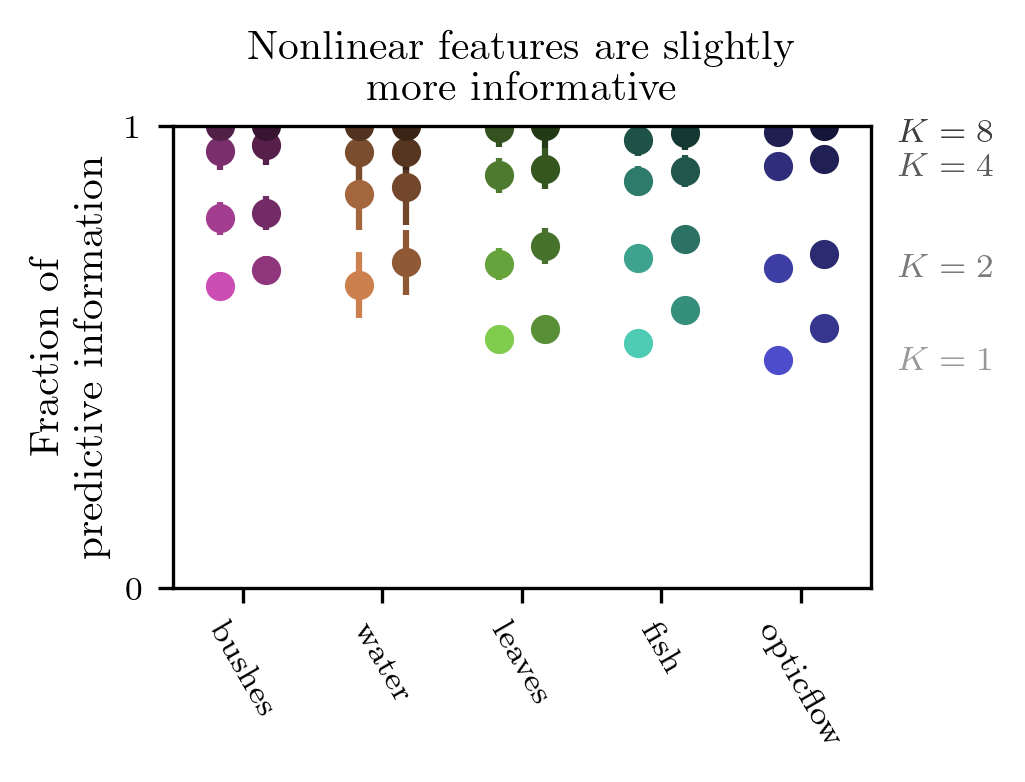

In [ ]:
alp = 0.1
margin = 0.5
fig, ax = plt.subplots(figsize=[6*plot_scale,4*plot_scale], dpi=300)
N_K = 4
spacing = 1/6

for j, stim in enumerate(stimuli):
    for i, K in enumerate(data[0].meta_neuron_array[:-1]):
        l = (N_K - i + 1) / (N_K + 1)
        I_max = np.amax(average_test[j])
        y = average_test[j][i] / I_max
        yerr = stdevs_test[j][i] / I_max
        # x = np.zeros(N_K) + j
        x = j - spacing
        # ax.semilogy(x, y, color=colors[j], label=stim)
        ax.errorbar(x, y, yerr, marker='o', color=colors[j] * l, label=stim)
        # ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
        if j == 4:
            ax.text(4.7, y-0.02, f"$K={K}$", color=np.ones((3))*0.6*l)

        I_max_nl = np.amax(average_nl_test[j])
        y = average_nl_test[j][i] / I_max_nl
        yerr = stdevs_nl_test[j][i] / I_max_nl
        x = j + spacing
        # ax.semilogy(x, y, color=colors[j], label=stim)
        ax.errorbar(x, y, yerr, marker='o', color=colors[j] * l*0.7, label=stim)
        # ax.fill_between(x, y-yerr, y+yerr, color=(0,0,0,alp), linewidth=0)
        # if j == 4:
            # ax.text(4.7, y-0.02, f"$K={K}$", color=np.ones((3))*0.6*l)


ax.set_ylim(0,1)
ax.set_xlim( -margin, 4 + margin)
ax.set_xticks(np.arange(len(stimuli)))
ax.set_xticklabels(stimuli)
ax.tick_params(axis='x', labelrotation=-60)
ax.set_yticks([0,1])
ax.set_ylabel("Fraction of\n predictive information")
ax.set_title("Nonlinear features are slightly\n more informative")    
# fig.savefig('./plots/compressibility across stim.svg', bbox_inches="tight")
# fig.savefig('./plots/compressibility across stim.png', dpi=3000)